# LoRA rank × base precision on a single T4: reproduction notebook

This notebook only calls the scripts in `scripts/`; all logic lives there. See `README.md` for the question, protocol and limitations.

**Runtime:** *Runtime → Change runtime type → T4 GPU.* The full grid (24 runs) takes roughly 2-3 GPU-hours; regenerating the figures from committed results takes seconds and needs no GPU.

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [2]:
REPO_URL = "https://github.com/<your-username>/<your-repo>.git"  # set before running

import os
if not os.path.exists("/content/repo"):
    !git clone -q {REPO_URL} /content/repo
%cd /content/repo
!git log -1 --oneline

/content/repo
b48fb21 (HEAD -> main, origin/main, origin/HEAD) first commit


In [3]:
!pip install -q -r requirements.txt
# Colab preinstalls torchao 0.10, which peft 0.21 rejects on import. This project does not use torchao.
!pip uninstall -q -y torchao
# If Colab prints "You must restart the runtime", do Runtime → Restart session, then re-run the cell above (not this one).

## Path 1: regenerate every figure from the committed raw results (no GPU needed)

In [4]:
!python scripts/make_figures.py

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/content/repo/results/runs.csv not found - run scripts/run_ablation.py first.


## Path 2: full re-run on your own GPU

Results go to `RESULTS_DIR`. A Colab session can drop mid-grid; `run_ablation.py` skips finished runs, so just re-run the cell. To survive a full disconnect, point `RESULTS_DIR` at Google Drive (uncomment the lines below).

In [5]:
RESULTS_DIR = "results_rerun"  # reviewers: keep this. Author's reference run: "results" (the committed folder)
# from google.colab import drive; drive.mount("/content/drive")
# RESULTS_DIR = "/content/drive/MyDrive/lora-t4-ablation/results"
!python scripts/env_info.py --results-dir {RESULTS_DIR}

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "colab": true,
  "git_commit": "b48fb21",
  "git_dirty": false,
  "cuda_runtime": "13.0",
  "cudnn": "92700",
  "gpu_name": "Tesla T4",
  "gpu_mem_total_mb": 14913,
  "gpu_capability": "7.5",
  "driver": "580.82.07",
  "torch": "2.11.0+cu130",
  "transformers": "5.21.0",
  "peft": "0.21.2",
  "bitsandbytes": "0.50.2",
  "accelerate": "1.15.0",
  "scikit-learn": "1.9.1",
  "numpy": "2.4.6",
  "pandas": "3.1.0",
  "matplotlib": "3.11.2"
}


In [6]:
# ~2 minute pipeline check on a tiny subset (writes to results_smoke/, never mixed with real results)
!python scripts/run_ablation.py --smoke --seed 0 --rank 8

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
1 configurations to run, 1 already in /content/repo/results_smoke/runs.csv

=== 1/1: fp16_r8_s0 ===
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[fp16_r8_s0] starting
Loading weights: 100% 290/290 [00:00<00:00, 363.60it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/content/repo/scripts/train_eval.py:166: UserWarning: Detected call of `lr_scheduler.step()` before `optimi

In [7]:
!python scripts/baseline_tfidf.py --results-dir {RESULTS_DIR}

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
{
  "model": "tfidf_logreg",
  "ngram_range": [
    1,
    2
  ],
  "C": 10.0,
  "val_acc_by_C": {
    "1.0": 0.8491508491508492,
    "10.0": 0.8931068931068931,
    "100.0": 0.8891108891108891
  },
  "test_acc": 0.8902597402597403,
  "test_macro_f1": 0.8903593720023817,
  "fit_seconds_cpu": 22.71,
  "n_train": 9002,
  "n_test": 3080
}


In [8]:
!python scripts/run_ablation.py --results-dir {RESULTS_DIR}

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
24 configurations to run, 0 already in results_rerun/runs.csv

=== 1/24: fp16_r4_s0 ===
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[fp16_r4_s0] starting
Loading weights: 100% 290/290 [00:00<00:00, 373.16it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/content/repo/scripts/train_eval.py:166: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`.

In [9]:
!python scripts/audit.py --results-dir {RESULTS_DIR}
!python scripts/make_figures.py --results-dir {RESULTS_DIR} --figures-dir {RESULTS_DIR}/figures

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
{
  "n_test": 3080,
  "exact_duplicates_in_train": 24,
  "near_duplicates_in_train": 124,
  "near_duplicate_cosine_threshold": 0.9,
  "accuracy_by_overlap": {
    "fp16_r16": {
      "n_seeds": 3,
      "acc_all": 0.9428571428571427,
      "acc_clean": 0.9418132611637349,
      "acc_overlap": 0.967741935483871
    },
    "fp16_r32": {
      "n_seeds": 3,
      "acc_all": 0.9426406926406926,
      "acc_clean": 0.94170049616599,
      "acc_overlap": 0.9650537634408604
    },
    "fp16_r4": {
      "n_seeds": 3,
      "acc_all": 0.9392857142857144,
      "acc_clean": 0.9380920162381597,
      "acc_overlap": 0.967741935483871
    },
    "fp16_r8": {
      "n_seeds": 3,
      "acc_all": 0.9404761904761906,
      "acc_clean": 0.939445196211096,
      "acc_overlap": 0.9650537634408604
 

## View results

| Base precision | Rank | Seeds | Test acc (%) | Macro-F1 (%) | Trainable params (M) | Peak train mem (GB) | Train time (min) | Batch-1 latency p50 / p95 (ms) | Throughput, batch 64 (ex/s) | Est. train compute (TFLOP) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| fp16 | 4 | 3 | 93.93 ± 0.15 | 93.93 | 2.27 | 6.04 | 4.2 ± 0.1 | 77.8 / 92.7 | 305 | 535 |
| fp16 | 8 | 3 | 94.05 ± 0.15 | 94.04 | 4.47 | 6.08 | 4.2 ± 0.0 | 79.0 / 93.1 | 308 | 538 |
| fp16 | 16 | 3 | 94.29 ± 0.09 | 94.28 | 8.87 | 6.16 | 4.2 ± 0.0 | 77.7 / 92.1 | 306 | 545 |
| fp16 | 32 | 3 | 94.26 ± 0.18 | 94.26 | 17.67 | 6.33 | 4.3 ± 0.0 | 77.8 / 92.4 | 304 | 558 |
| nf4 | 4 | 3 | 93.96 ± 0.06 | 93.96 | 2.27 | 5.54 | 4.3 ± 0.0 | 93.7 / 107.1 | 320 | 535 |
| nf4 | 8 | 3 | 94.15 ± 0.05 | 94.15 | 4.47 | 5.58 | 4.2 ± 0.0 | 94.7 / 109.6 | 323 | 538 |
| nf4 | 16 | 3 | 94.17 ± 0.21 | 94.17 | 8.87 | 5.66 | 4.3 ± 0.1 | 97.0 / 110.5 | 321 | 545 |
| nf4 | 32 | 3 | 94.46 ± 0.05 | 94.45 | 17.67 | 5.82 | 4.3 ± 0.0 | 95.3 / 108.7 | 318 | 558 |
| TF-IDF + LogReg (CPU) | – | 1 | 89.03 | 89.04 | – | – | 0.4 (CPU) | – | – | – |

Values are mean ± 1 sample SD across seeds. Test-set sampling error alone is about ±0.43 pp (binomial SE, n = 3080), so differences smaller than roughly 2 × that are not resolvable on this test set.
Hardware and software: Tesla T4 | torch 2.11.0+cu130 | Qwen2.5-0.5B on Banking77.
Train/test overlap: 24 exact and 124 near-duplicate test items (TF-IDF cosine >= 0.9); see results/audit/.


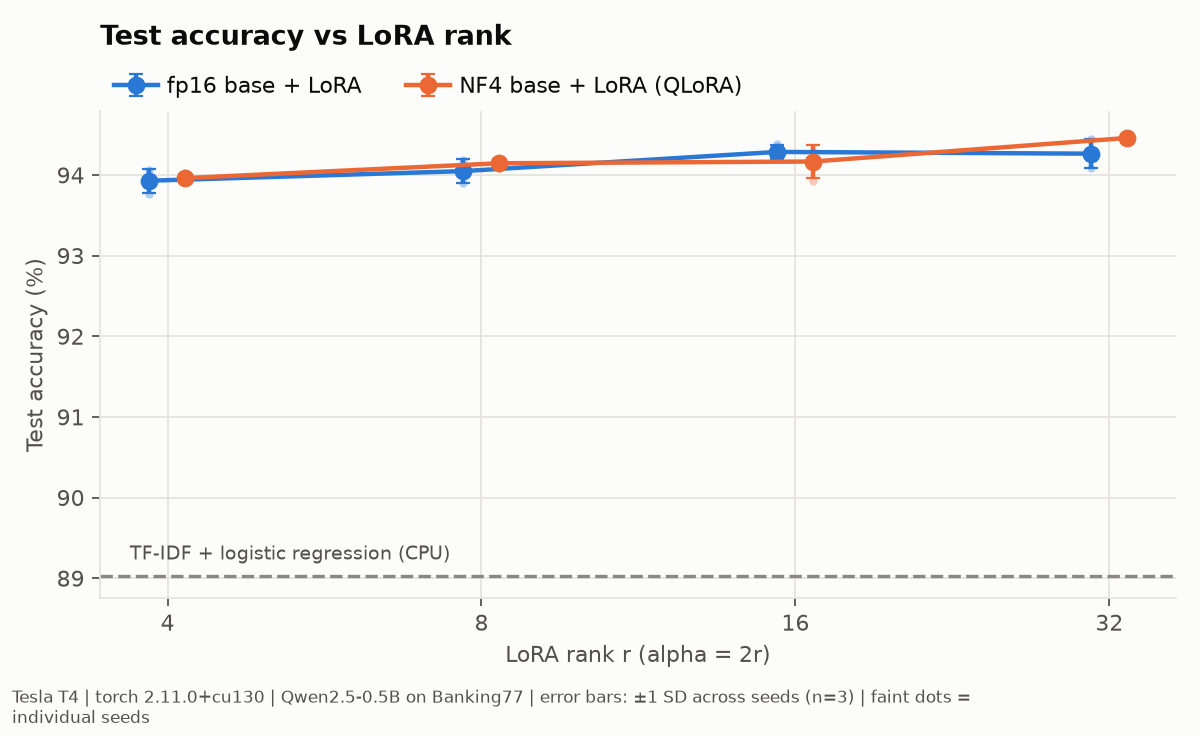

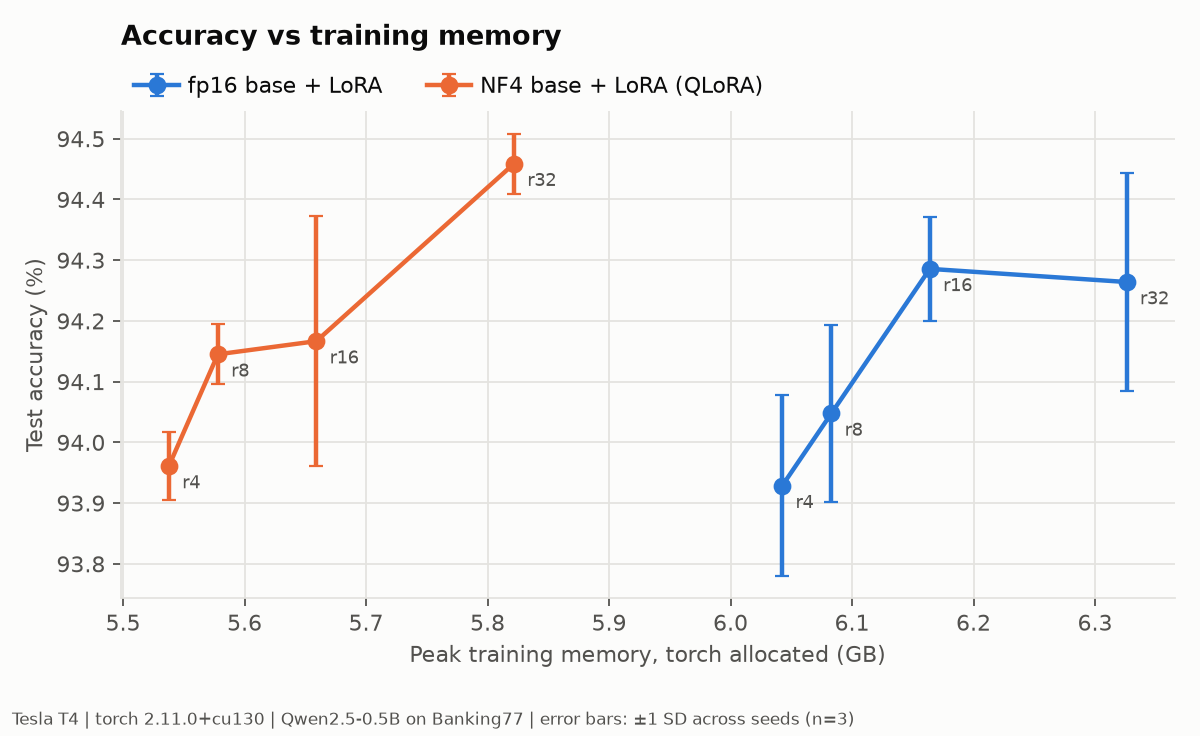

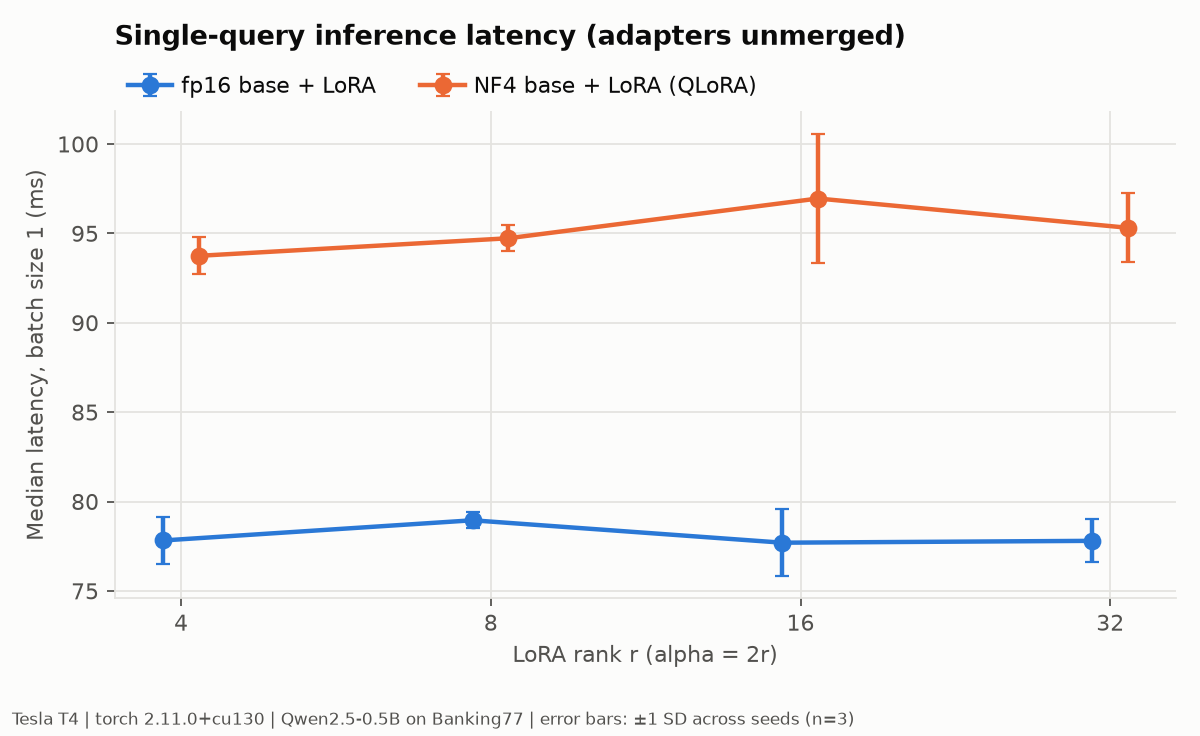

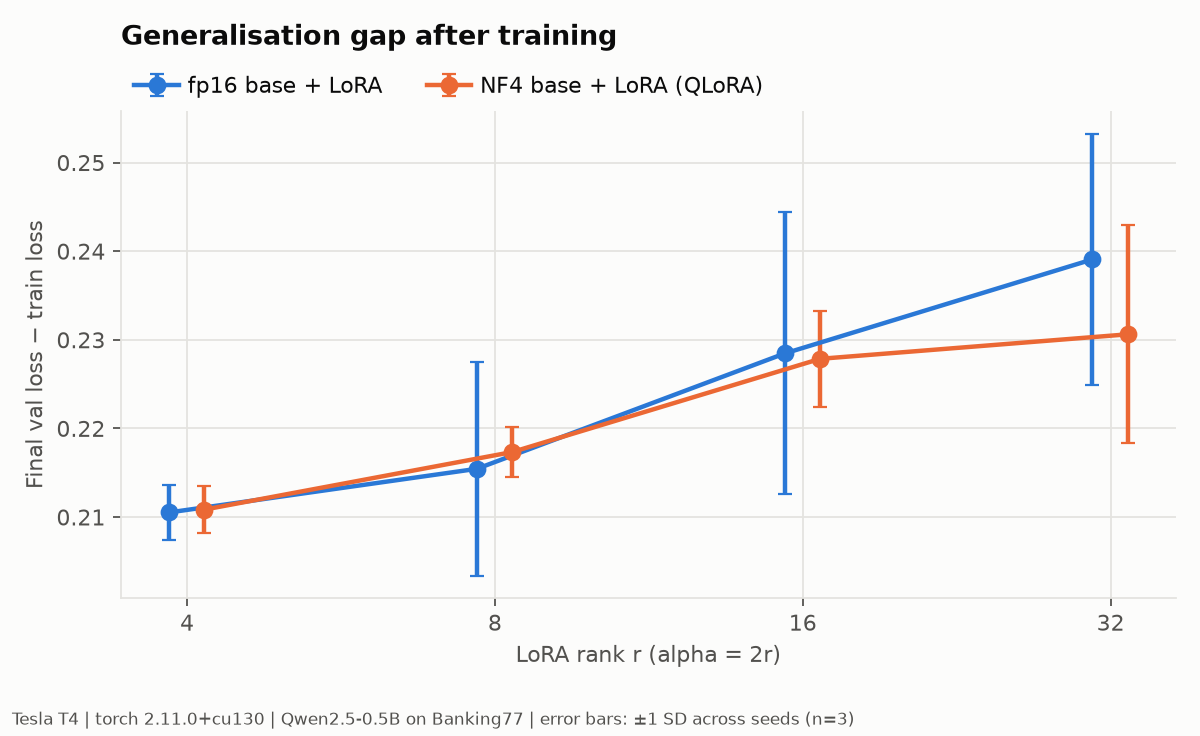

In [10]:
from pathlib import Path
from IPython.display import Image, Markdown, display

out = Path(RESULTS_DIR) if Path(RESULTS_DIR, "summary.md").exists() else Path("results")
fig_dir = out / "figures" if (out / "figures").exists() else Path("figures")
display(Markdown(out.joinpath("summary.md").read_text()))
for png in sorted(fig_dir.glob("*.png")):
    display(Image(str(png)))

In [11]:
# Optional: download the new results to commit them back to the repo
!zip -qr results_rerun.zip {RESULTS_DIR}
from google.colab import files; files.download("results_rerun.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>